# Step 4b — Apply the Winning Model: CLV and Risk/Value Segmentation

Model selection now happens in `model_comparison.ipynb` (7 scikit-learn
classifiers, tuned and compared on ROC-AUC) — this notebook just loads
whichever model won (`models/best_churn_model.joblib`) and applies it to the
full customer base: out-of-fold risk scores, CLV, and the risk x value
quadrant. Run `model_comparison.ipynb` first.

**Input:** `data/cleaned_telco.csv`, `models/best_churn_model.joblib`
**Output:** `data/risk_value_segments.csv`, plus 1 chart rendered inline below

In [1]:
import os
import sys


def find_project_root(marker="requirements.txt"):
    path = os.getcwd()
    for _ in range(5):
        if os.path.exists(os.path.join(path, marker)):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not locate project root (looked for {marker})")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, os.path.join(PROJECT_ROOT, "scripts"))
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

PROJECT_ROOT = C:\Users\DEVKUMAR\OneDrive\Desktop\DA_Project


In [2]:
from plot_style import CATEGORICAL, CHURN_COLOR, RETAINED_COLOR, INK_SECONDARY, apply_style
from feature_eng import engineer_features, FEATURES

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

CLEANED_PATH = os.path.join(PROJECT_ROOT, "data", "cleaned_telco.csv")
OUT_PATH = os.path.join(PROJECT_ROOT, "data", "risk_value_segments.csv")
MODEL_PATH = os.path.join(PROJECT_ROOT, "models", "best_churn_model.joblib")

apply_style()
RANDOM_STATE = 42

## Load data, engineer features, load the winning model

In [3]:
df = pd.read_csv(CLEANED_PATH)
df = engineer_features(df)

X = df[FEATURES]
y = df["ChurnFlag"]

winning_pipe = joblib.load(MODEL_PATH)
winner_name = type(winning_pipe.named_steps["clf"]).__name__
print(f"Loaded winning model: {winner_name}")
print(f"Population: {len(df)} customers")

Loaded winning model: LogisticRegression
Population: 7043 customers


## CLV

**Historical CLV** = actual `TotalCharges` to date.

**Projected CLV** = `TotalCharges` to date + `MonthlyCharges x expected remaining tenure`,
where expected remaining tenure is a transparent heuristic — the average
total tenure observed for a customer's contract type, minus their tenure so
far. Not a survival/BG-NBD model, just an explainable proxy given this
snapshot dataset can't support a rigorous probabilistic CLV estimate.

In [4]:
df["Historical_CLV"] = df["TotalCharges"]

avg_tenure_by_contract = df.groupby("Contract")["tenure"].transform("mean")
remaining_tenure = (avg_tenure_by_contract - df["tenure"]).clip(lower=0)
df["Projected_CLV"] = df["TotalCharges"] + df["MonthlyCharges"] * remaining_tenure
df[["Historical_CLV", "Projected_CLV"]].describe()

,Historical_CLV,Projected_CLV
count,7043.000000,7043.000000
mean,2279.734304,2650.415550
std,2266.794470,2067.212488
min,0.000000,314.690761
25%,398.550000,1133.876239
50%,1394.550000,1710.522129
75%,3786.600000,3999.900000
max,8684.800000,8684.800000


## Out-of-fold churn risk score for every customer

5-fold cross-validation, refitting a fresh clone of the winning pipeline on
each fold, so every customer gets an unbiased predicted probability (never
scored by a model that was trained on them). The test-set ROC-AUC that
picked this model already came from `model_comparison.ipynb`'s genuinely
held-out test set — this OOF pass is only for scoring the full population
for the risk/value segmentation below.

In [5]:
oof_pipe = clone(winning_pipe)
oof_proba = cross_val_predict(oof_pipe, X, y, cv=5, method="predict_proba", n_jobs=-1)[:, 1]
df["Churn_Risk_Score"] = oof_proba
print(f"Done -- 5-fold OOF churn risk score ({winner_name}) computed for all", len(df), "customers")

Done -- 5-fold OOF churn risk score (LogisticRegression) computed for all 7043 customers


## Risk x Value quadrant

In [6]:
risk_high = df["Churn_Risk_Score"] >= 0.5
value_high = df["Projected_CLV"] >= df["Projected_CLV"].median()


def quadrant(risk, value):
    if value and risk:
        return "High Value / High Risk (priority retention)"
    if value and not risk:
        return "High Value / Low Risk (protect & reward)"
    if not value and risk:
        return "Low Value / High Risk (low priority)"
    return "Low Value / Low Risk (monitor)"


df["Risk_Value_Quadrant"] = [quadrant(r, v) for r, v in zip(risk_high, value_high)]

quad_order = [
    "High Value / High Risk (priority retention)",
    "High Value / Low Risk (protect & reward)",
    "Low Value / High Risk (low priority)",
    "Low Value / Low Risk (monitor)",
]
quad_counts = df["Risk_Value_Quadrant"].value_counts().reindex(quad_order)
print("Risk x Value quadrant counts:\n", quad_counts)
print("\nRevenue at stake (Projected_CLV sum) by quadrant:")
print(df.groupby("Risk_Value_Quadrant")["Projected_CLV"].sum().reindex(quad_order).round(0))

Risk x Value quadrant counts:
 Risk_Value_Quadrant
High Value / High Risk (priority retention)    1095
High Value / Low Risk (protect & reward)       2427
Low Value / High Risk (low priority)           1741
Low Value / Low Risk (monitor)                 1780
Name: count, dtype: int64

Revenue at stake (Projected_CLV sum) by quadrant:
Risk_Value_Quadrant
High Value / High Risk (priority retention)     3613108.0
High Value / Low Risk (protect & reward)       11296557.0
Low Value / High Risk (low priority)            2060347.0
Low Value / Low Risk (monitor)                  1696865.0
Name: Projected_CLV, dtype: float64


## Save risk/value segments

In [7]:
keep_cols = ["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges",
             "Historical_CLV", "Projected_CLV", "Churn_Risk_Score", "Risk_Value_Quadrant",
             "Churn", "ChurnFlag"]
df[keep_cols].to_csv(OUT_PATH, index=False)
print(f"Wrote {len(df)} rows to {OUT_PATH}")

Wrote 7043 rows to C:\Users\DEVKUMAR\OneDrive\Desktop\DA_Project\data\risk_value_segments.csv


## Chart: risk x value scatter

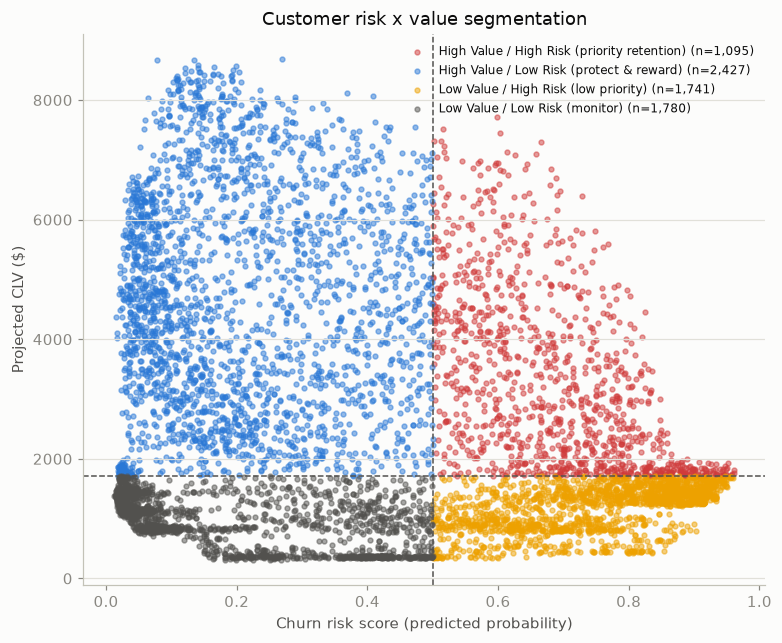

In [8]:
quad_colors = {
    "High Value / High Risk (priority retention)": CHURN_COLOR,
    "High Value / Low Risk (protect & reward)": RETAINED_COLOR,
    "Low Value / High Risk (low priority)": CATEGORICAL[3],
    "Low Value / Low Risk (monitor)": INK_SECONDARY,
}
fig, ax = plt.subplots(figsize=(8, 6.5))
for quad in quad_order:
    sub = df[df["Risk_Value_Quadrant"] == quad]
    ax.scatter(sub["Churn_Risk_Score"], sub["Projected_CLV"], s=10, alpha=0.5,
               color=quad_colors[quad], label=f"{quad} (n={len(sub):,})")
ax.axvline(0.5, color=INK_SECONDARY, linewidth=1, linestyle="--")
ax.axhline(df["Projected_CLV"].median(), color=INK_SECONDARY, linewidth=1, linestyle="--")
ax.set_xlabel("Churn risk score (predicted probability)")
ax.set_ylabel("Projected CLV ($)")
ax.set_title("Customer risk x value segmentation")
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.show()